In [1]:
import torch

print(torch.__version__)
print(torch.version.cuda)
print(torch.cuda.is_available())

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

2.10.0+cu128
12.8
True
NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
import gymnasium as gym
import matplotlib.pyplot as plt
import ale_py

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 触发 ale_py 把自己的环境写进 Gymnasium 的环境注册表，注册完成后，gym.make("ALE/xxx-v5") 才能找到对应环境
# gym.register_envs(ale_py)，不加这句话没有报错，可以不使用

# =====================
# 1. 创建 Atari 环境
# =====================
# env_rgb：不弹窗口，适合取画面数组、做训练
# env_human：弹游戏窗口，适合人工观察
env_rgb = gym.make("ALE/SpaceInvaders-v5", render_mode="rgb_array")
env_human = gym.make("ALE/SpaceInvaders-v5", render_mode="human")


In [3]:
# =====================
# 2. 重置环境
# =====================
# 新版 Gymnasium 的 reset() 返回 (observation, info)
obs_rgb, info_rgb = env_rgb.reset()
obs_human, info_human = env_human.reset()

print("SpaceInvaders 环境启动成功")

SpaceInvaders 环境启动成功


In [4]:
# =====================
# 3. 查看观察空间信息
# =====================
print(f"RGB 环境观察形状: {obs_rgb.shape}")
print(f"Human 环境观察形状: {obs_human.shape}")
print(f"RGB 环境数据类型: {obs_rgb.dtype}")
print(f"Human 环境数据类型: {obs_human.dtype}")

# 打印画面数组（数据量较大，控制台会输出很多像素值）
print("RGB 环境初始画面数组：")
print(obs_rgb)

RGB 环境观察形状: (210, 160, 3)
Human 环境观察形状: (210, 160, 3)
RGB 环境数据类型: uint8
Human 环境数据类型: uint8
RGB 环境初始画面数组：
[[[ 0  0  0]
  [ 0  0  0]
  [ 0  0  0]
  ...
  [ 0  0  0]
  [ 0  0  0]
  [ 0  0  0]]

 [[ 0  0  0]
  [ 0  0  0]
  [ 0  0  0]
  ...
  [ 0  0  0]
  [ 0  0  0]
  [ 0  0  0]]

 [[ 0  0  0]
  [ 0  0  0]
  [ 0  0  0]
  ...
  [ 0  0  0]
  [ 0  0  0]
  [ 0  0  0]]

 ...

 [[80 89 22]
  [80 89 22]
  [80 89 22]
  ...
  [80 89 22]
  [80 89 22]
  [80 89 22]]

 [[80 89 22]
  [80 89 22]
  [80 89 22]
  ...
  [80 89 22]
  [80 89 22]
  [80 89 22]]

 [[80 89 22]
  [80 89 22]
  [80 89 22]
  ...
  [80 89 22]
  [80 89 22]
  [80 89 22]]]


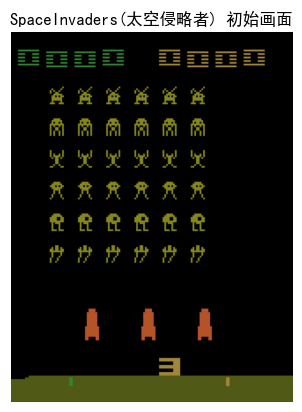

In [5]:
# =====================
# 4. 渲染并显示画面
# =====================
# rgb_array 模式下，render() 返回当前帧的 NumPy 数组
frame = env_rgb.render()
plt.imshow(frame)
plt.axis("off")
plt.title("SpaceInvaders(太空侵略者) 初始画面")
plt.show()

# 关闭 rgb_array 环境
env_rgb.close()

In [6]:
# =====================
# 5. 执行一步随机动作
# =====================
# 从动作空间中随机采样一个动作
action = env_human.action_space.sample()

# 执行动作，新版 step() 返回 5 个值
obs, reward, terminated, truncated, info = env_human.step(action)

print(f"执行动作: {action}")
print(f"新观察形状: {obs.shape}")
print(f"获得奖励: {reward}")
print(f"回合是否结束: {terminated}")
print(f"是否被截断: {truncated}")
print(f"额外信息: {info}")

# 关闭 human 环境，释放窗口资源
env_human.close()

执行动作: 1
新观察形状: (210, 160, 3)
获得奖励: 0.0
回合是否结束: False
是否被截断: False
额外信息: {'lives': 3, 'episode_frame_number': 4, 'frame_number': 4}


In [7]:
print(env_human.action_space.n)          # 动作数量
print(env_human.unwrapped.get_action_meanings()) # 动作内容

6
['NOOP', 'FIRE', 'RIGHT', 'LEFT', 'RIGHTFIRE', 'LEFTFIRE']
